In [1]:
from v2_data_preparation import (
    load_and_prepare_data, slice_by_dates, handle_duplicate_values, reindex_daily, filter_by_reflectance, filter_clouds, filter_shadows,
    handle_outliers, calculate_stats_from_random_points, filter_columns, handle_missing_values, attach_spacecraft_column, process_insitu
)
from v2_sensor_fusion import fuse_sensors
from v2_feature_engineering import build_features_dataset, join_datasets, build_features_dataset_v2
from v3_modelling_framework import split_data, define_model_pipeline_and_grid, tune_and_train_model, evaluate_model, predict_dataset, calculate_shap_values

from v2_visualization import (
    obs_data, format_metrics_table, plot_landsat_bands, plot_residuals_boxplot, 
    plot_pred_vs_real, plot_timeseries_results, plot_timeseries_results2, plot_shap)

import shap
import pandas as pd

/opt/miniconda3/envs/ML/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# -----------------------------
# 1. Study site selection and config
# -----------------------------

study_site = 'SDH1'
start_date = '2000'
end_date = '2026'

if study_site == 'SDH1':
    target = 'SDH1PS01_gw-depth_m'
    insitu_filepath = '../data/processed/in-situ/SDH1_daily-insitu-data.csv'
    viirs_fp = '../data/processed/satellites/SDH1_VIIRS_2012_01_2026_10.csv'
    landsat_fp = '../data/processed/satellites/SDH1_L_30m_2012-01-01_2026-10-11.csv'

elif study_site == 'SDH2':
    target = 'SDH2PP01_gw-depth_m'
    insitu_filepath = '../data/processed/in-situ/SDH2_daily-insitu-data.csv'
    modis_filepath = '../data/processed/satellites/SDH2_MT_500m_2000-03_2026-06.csv'
    landsat_filepath = '../data/processed/satellites/SDH2_L_30m_2000-02_2026-06.csv'

else:
    print(f'{study_site} not supported as study site')

LANDSAT_BLUE = 'blue_median'
LANDSAT_GREEN = 'green_median'
LANDSAT_RED = 'red_median'
LANDSAT_NIR = 'nir_median'
LANDSAT_SWIR1 = 'swir1_median'
LANDSAT_SWIR2 = 'swir2_median'

VIIRS_BLUE = 'Nadir_Reflectance_M3'
VIIRS_GREEN = 'Nadir_Reflectance_M4'
VIIRS_RED = 'Nadir_Reflectance_I1'
VIIRS_NIR = 'Nadir_Reflectance_I2'
VIIRS_SWIR1 = 'Nadir_Reflectance_I3'
VIIRS_SWIR2 = 'Nadir_Reflectance_M11'

landsat_cols = [LANDSAT_BLUE, LANDSAT_GREEN, LANDSAT_RED, LANDSAT_NIR, LANDSAT_SWIR1, LANDSAT_SWIR2]
viirs_cols = [VIIRS_BLUE, VIIRS_GREEN, VIIRS_RED, VIIRS_NIR, VIIRS_SWIR1, VIIRS_SWIR2]

# Format -> 'Final Output Name': ('Landsat_Column_Name', 'VIIRS_Column_Name')
band_mapping = {
    'blue':  (LANDSAT_BLUE,  VIIRS_BLUE),
    'green': (LANDSAT_GREEN, VIIRS_GREEN),
    'red':   (LANDSAT_RED,   VIIRS_RED),
    'nir':   (LANDSAT_NIR,   VIIRS_NIR),
    'swir1': (LANDSAT_SWIR1, VIIRS_SWIR1),
    'swir2': (LANDSAT_SWIR2, VIIRS_SWIR2)
}

features = [
    'ndvi',
    'gndvi',
    'ndwi',
    'mndwi',
    'ndmi',
    'ndmi2',
    'str1',
    'str2',
]

start = '2012-01-01'
end = '2026-11-01'

In [3]:
# -----------------------------
# 2. Input data preprocessing
# -----------------------------

landsat = (
    load_and_prepare_data(filepath=landsat_fp)
    .pipe(slice_by_dates, startDate=start, endDate=end)
    #.pipe(filter_by_reflectance)
    .pipe(handle_duplicate_values)      # no tiene efecto
    #.pipe(reindex_daily)               # no deberia ser necesario
    .pipe(handle_outliers, z_thresh=3)
    .pipe(calculate_stats_from_random_points, minPoints=10)
    .pipe(filter_columns, cols_to_keep=landsat_cols)
    #.pipe(filter_clouds, column_name='nir_median', max_threshold=0.7)       # este es aceptable, elimina un par de caso de nubes
    #.pipe(filter_shadows, column_name='swir2_median', min_threshold=0.1)   # no es un buen filtro
)

viirs = (
    load_and_prepare_data(filepath=viirs_fp)
    .pipe(filter_columns, cols_to_keep=viirs_cols)
    .pipe(slice_by_dates, startDate=start, endDate=end)
    .pipe(filter_by_reflectance)
    .pipe(reindex_daily)                # suma una fila
    .pipe(handle_outliers, z_thresh=3)  # hay valores que se vuelven nan
    .pipe(handle_missing_values, method='time')
)

insitu_df = process_insitu(
    filepath=insitu_filepath,
    start_date='2024-05-24',
    end_date='2026-06-26',
    cols_to_keep=target,
    outlier_threshold=3.0
    )

In [4]:
# -----------------------------
# 3. Daily satellite series
# -----------------------------

sensor_fusion_results = fuse_sensors(
    modis_df=viirs,
    landsat_df=landsat,
    band_mapping=band_mapping,
    test_size=0.3,
    sigma_threshold=3.0,
    verbose_summary=False,
    verbose_plots=False
)

# plot_residuals_boxplot(sensor_fusion_results['residuals'])
# plot_landsat_bands(
#     daily_df=sensor_fusion_results['anchored'],
#     original_df=landsat_df,
#     residuals_df=sensor_fusion_results['residuals_interpolated'],
#     start='2021',
#     end='2026'
# )
# plot_landsat_bands(
#     daily_df=sensor_fusion_results['predicted'],
#     original_df=landsat_df,
#     residuals_df=sensor_fusion_results['residuals'],
#     start='2021',
#     end='2026'
# )

metrics_df = format_metrics_table(sensor_fusion_results['metrics'])
print(metrics_df.to_string())


Processing blue (532 coincident points)
Train - R2: 0.457 | MAE: 0.056 | RMSE: 0.072
Test  - R2: 0.411  | MAE: 0.056  | RMSE: 0.072

Processing green (535 coincident points)
Train - R2: 0.442 | MAE: 0.059 | RMSE: 0.077
Test  - R2: 0.506  | MAE: 0.056  | RMSE: 0.071

Processing red (533 coincident points)
Train - R2: 0.614 | MAE: 0.048 | RMSE: 0.07
Test  - R2: 0.702  | MAE: 0.04  | RMSE: 0.055

Processing nir (536 coincident points)
Train - R2: 0.611 | MAE: 0.046 | RMSE: 0.067
Test  - R2: 0.655  | MAE: 0.044  | RMSE: 0.061

Processing swir1 (536 coincident points)
Train - R2: 0.597 | MAE: 0.055 | RMSE: 0.072
Test  - R2: 0.64  | MAE: 0.056  | RMSE: 0.07

Processing swir2 (536 coincident points)
Train - R2: 0.553 | MAE: 0.06 | RMSE: 0.076
Test  - R2: 0.628  | MAE: 0.06  | RMSE: 0.073
                 r2    mae   rmse
band  subset                     
blue  train   0.457  0.056  0.072
      test    0.411  0.056  0.072
green train   0.442  0.059  0.077
      test    0.506  0.056  0.071
red

In [50]:
# -----------------------------
# 4. Predictors and target processing
# -----------------------------

# features_dataset, cc_report, pca_model = build_features_dataset(
#     remote_df=sensor_fusion_results['predicted'],
#     insitu_df=insitu_df,
#     target_col=target,
#     spectral_bands_cols=modis_cols,
#     pca_components=2,
#     verbose_pca=True,
#     rolling_windows=[7],
#     rolling_stats=['mean'],
#     max_cc_lag=8,
#     min_corr_thresh=0.1,
#     top_k_lags=5,
#     random_state=42
# )

features_dataset = build_features_dataset_v2(
    remote_df=sensor_fusion_results['predicted'],
    spectral_bands_cols=viirs_cols,
    pca_components=3,
    verbose_pca=True,
    past_lags=[0],
    future_lags=[0],
    random_state=42
)

training_df = join_datasets(
    df1=insitu_df[[target]],
    df2=features_dataset,
    how='inner'
    )


print(f'\nTraining dataset: {training_df.shape[0]} rows, {training_df.shape[1]} columns')


--- PCA Evaluation ---
Component 1 explains: 56.06% of the variance
Component 2 explains: 24.32% of the variance
Component 3 explains: 10.79% of the variance
Total variance retained: 91.17%

Contribution per feature:
        PC_1   PC_2   PC_3
blue   0.299 -0.238  0.175
green  0.299 -0.247  0.182
red    0.326  0.090  0.297
nir    0.328  0.105  0.237
swir1  0.343  0.095  0.009
swir2  0.330 -0.125 -0.115
ndvi  -0.221  0.007 -0.436
gndvi  0.047  0.529  0.058
ndwi  -0.047 -0.529 -0.058
mndwi -0.166 -0.442  0.266
ndmi  -0.225 -0.055  0.542
ndmi2 -0.223  0.252  0.412
str1  -0.333 -0.107  0.099
str2  -0.297  0.078  0.194

Training dataset: 764 rows, 8 columns


In [51]:
# -----------------------------
# 5. Model training and evaluation
# -----------------------------

data_split = split_data(
    df=training_df,
    target=target,
    test_start_date='2025-05-23',    # 2025-05-18
    chronological_order=False
)

X_train = data_split['X_train']
X_test = data_split['X_test']
y_train = data_split['y_train']
y_test = data_split['y_test']

opt_results = tune_and_train_model(
    X_train=X_train,
    y_train=y_train,
    model_type='rf',
    n_splits=3,
    max_train_size=None,
    test_size=30,
    gap=1,
    nested_cv=True
)
print("\n--- Hiperparámetros seleccionados ---")
print('Best CV RMSE:')
print(opt_results['best_cv_rmse'])
for parameter_name, parameter_value in opt_results[
    "best_hyperparameters"
].items():
    print(f"{parameter_name}: {parameter_value}")

best_pipeline = opt_results["best_pipeline"]

y_pred_test, y_pred_train, metrics_test, metrics_train = evaluate_model(
    model=best_pipeline,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test,
)

predictions_df = predict_dataset(
    df=training_df,
    model=best_pipeline,
    target=target
)

Training samples: 399 | Testing samples: 365

--- Hiperparámetros seleccionados ---
Best CV RMSE:
0.06839446725121924
regressor__max_depth: None
regressor__min_samples_split: 10
regressor__n_estimators: 50

--- Training performance ---
R²:   0.985
RMSE:   0.013
MAE:   0.009
PBIAS:   -0.085

--- Testing performance ---
R²:   0.602
RMSE:   0.086
MAE:   0.067
PBIAS:   -6.383


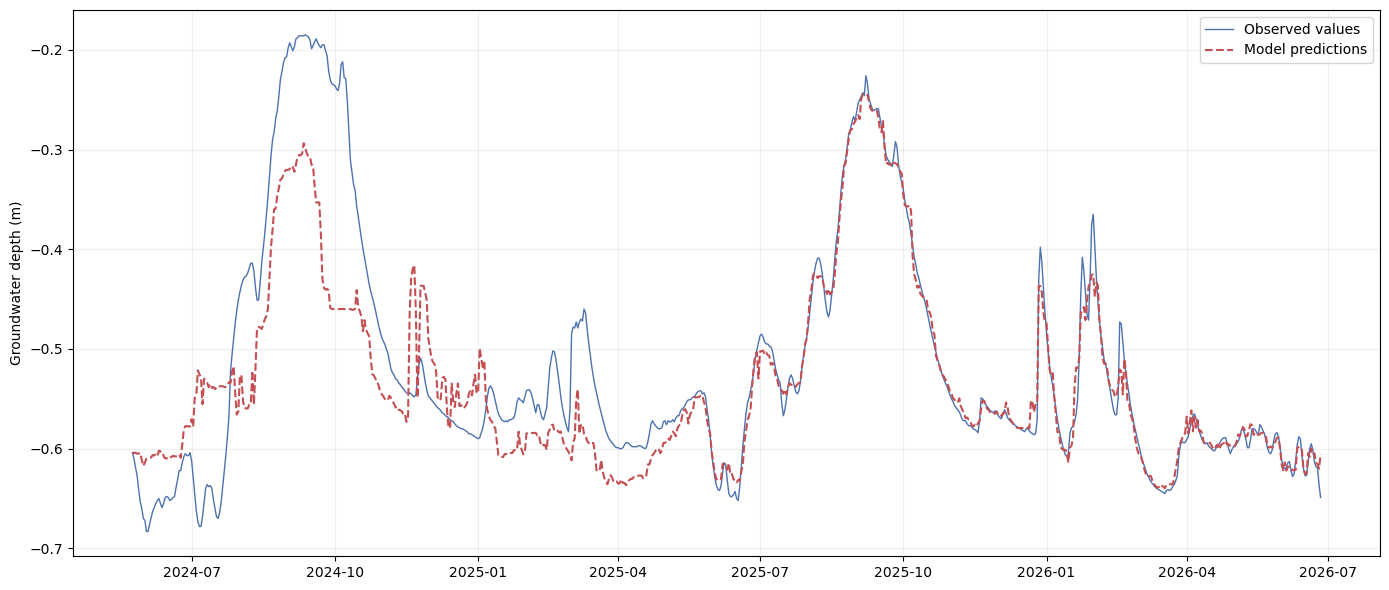

In [52]:
plot_timeseries_results(df=predictions_df)

In [53]:
# shap_values = None

# shap_values = calculate_shap_values(
#     model=best_pipeline,
#     X=X_test,
#     sample_size=None
# )